## Import Libraries  

In [1]:
#import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, RFE
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    balanced_accuracy_score,
    f1_score
)
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
import joblib as jo
import warnings
warnings.filterwarnings('ignore')

 ## Fetch Data From MySQL Database

In [2]:
# connection = mysql.connector.connect (
#     host = '127.0.0.1',
#     user ='root',
#     password ='',
#      database = 'project_pattern'
# )

In [3]:
#query_1 = "select * from conflict_events" 

In [4]:
#query_2= "select * from world_trade"

In [5]:
#df_war = pd.read_sql(query_1 , connection)

In [6]:
#df_trade = pd.read_sql(query_2 , connection)

## Data Preprocessing

### Data Representation

In [7]:
#df_war.info()

In [8]:
#df_war.columns

In [9]:
#df_war.shape

In [10]:
#df_trade.info()

In [11]:
#df_trade.columns

In [12]:
#df_trade.shape

In [13]:
#df_trade_melted = df_trade.melt(
 #   id_vars=['Country Name', 'Country Code'], 
  #  var_name='year', 
 #   value_name='trade_value'
#)

In [14]:
#df_trade_melted['year'] = pd.to_numeric(df_trade_melted['year'], errors='coerce')

In [15]:
#df_trade_melted.dropna(subset=['year', 'trade_value'], inplace=True)
#df_trade_melted['year'] = df_trade_melted['year'].astype(int)

In [16]:
#df_trade_melted.head()

In [17]:
#features_needed = [
   # 'year', 'country', 'region', 'type_of_violence', 
  #  'latitude', 'longitude', 'number_of_sources', 
 #   'best', 'deaths_a', 'deaths_b', 'deaths_civilians'
#]

In [18]:
#df_war_selected = df_war[features_needed].copy()

In [19]:
#df_final = pd.merge(
  #  df_war_selected, 
   # df_trade_melted, 
   # left_on=['country', 'year'], 
  #  right_on=['Country Name', 'year'], 
   # how='left'
#)

In [20]:
import pandas as pd

df_final = pd.read_csv("final_cleaned_data.csv")
print(df_final.shape)
display(df_final.head())

(126896, 17)


,year,country,region,type_of_violence,latitude,longitude,number_of_sources,best,deaths_a,deaths_b,deaths_civilians,Country Name,Country Code,trade_value,total_deaths,intensity_level,intensity_numeric
0,1989,Nicaragua,Americas,1,12.083333,-85.166667,2,1,1,0,0,Nicaragua,NIC,97.728684,1,Low,0
1,1989,El Salvador,Americas,1,13.833300,-88.916700,5,1368,237,1050,81,El Salvador,SLV,36.928296,1368,High,2
2,1989,El Salvador,Americas,1,13.701265,-89.209392,1,5,0,5,0,El Salvador,SLV,36.928296,5,Low,0
3,1989,India,Asia,1,33.916670,76.666670,-1,3,0,3,0,India,IND,15.168132,3,Low,0
4,1989,Israel,Middle East,1,31.902561,35.195547,-1,1,0,1,0,Israel,ISR,62.899314,1,Low,0


In [21]:
df_final.head()

,year,country,region,type_of_violence,latitude,longitude,number_of_sources,best,deaths_a,deaths_b,deaths_civilians,Country Name,Country Code,trade_value,total_deaths,intensity_level,intensity_numeric
0,1989,Nicaragua,Americas,1,12.083333,-85.166667,2,1,1,0,0,Nicaragua,NIC,97.728684,1,Low,0
1,1989,El Salvador,Americas,1,13.833300,-88.916700,5,1368,237,1050,81,El Salvador,SLV,36.928296,1368,High,2
2,1989,El Salvador,Americas,1,13.701265,-89.209392,1,5,0,5,0,El Salvador,SLV,36.928296,5,Low,0
3,1989,India,Asia,1,33.916670,76.666670,-1,3,0,3,0,India,IND,15.168132,3,Low,0
4,1989,Israel,Middle East,1,31.902561,35.195547,-1,1,0,1,0,Israel,ISR,62.899314,1,Low,0


In [22]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126896 entries, 0 to 126895
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   year               126896 non-null  int64  
 1   country            126896 non-null  object 
 2   region             126896 non-null  object 
 3   type_of_violence   126896 non-null  int64  
 4   latitude           126896 non-null  float64
 5   longitude          126896 non-null  float64
 6   number_of_sources  126896 non-null  int64  
 7   best               126896 non-null  int64  
 8   deaths_a           126896 non-null  int64  
 9   deaths_b           126896 non-null  int64  
 10  deaths_civilians   126896 non-null  int64  
 11  Country Name       126896 non-null  object 
 12  Country Code       126896 non-null  object 
 13  trade_value        126896 non-null  float64
 14  total_deaths       126896 non-null  int64  
 15  intensity_level    126896 non-null  object 
 16  in

### Data Cleaning

In [23]:
df_final['trade_value'] = pd.to_numeric(df_final['trade_value'], errors='coerce')

In [24]:
df_final.dropna(subset=['trade_value'], inplace=True)

In [25]:
df_final.isnull().sum().sum()

np.int64(0)

In [26]:
df_final.duplicated().sum()

np.int64(0)

In [27]:
df_final.drop_duplicates(inplace=True)

In [28]:
df_final.duplicated().sum()

np.int64(0)

In [29]:
df_final.shape[0]

126896

In [30]:
df_final['region']  = df_final['region'].str.strip()
df_final['country'] = df_final['country'].str.strip()

In [31]:
df_final.sort_values(by='year', inplace=True)

In [32]:
df_final.to_csv('final_cleaned_data.csv', index=False)

In [33]:
df_final.head()

,year,country,region,type_of_violence,latitude,longitude,number_of_sources,best,deaths_a,deaths_b,deaths_civilians,Country Name,Country Code,trade_value,total_deaths,intensity_level,intensity_numeric
0,1989,Nicaragua,Americas,1,12.083333,-85.166667,2,1,1,0,0,Nicaragua,NIC,97.728684,1,Low,0
857,1989,Lebanon,Middle East,2,33.485833,35.518056,-1,5,0,0,0,Lebanon,LBN,109.925089,0,Low,0
856,1989,South Africa,Africa,2,-30.025295,30.861297,-1,0,0,0,0,South Africa,ZAF,42.699765,0,Low,0
855,1989,Uganda,Africa,1,3.000000,31.166667,-1,33,1,32,0,Uganda,UGA,26.047629,33,Medium,1
854,1989,Lebanon,Middle East,2,33.481889,35.499247,-1,6,0,0,0,Lebanon,LBN,109.925089,0,Low,0


In [34]:
df_final.shape

(126896, 17)

#### Outlier

In [35]:
# Outlier Removal (IQR)
Q1 = df_final['trade_value'].quantile(0.25)
Q3 = df_final['trade_value'].quantile(0.75)
IQR = Q3 - Q1
df_cleaned = df_final[
    (df_final['trade_value'] >= Q1 - 1.5*IQR) &
    (df_final['trade_value'] <= Q3 + 1.5*IQR)
].copy()

In [36]:
df_cleaned.shape

(124652, 17)

## Feature Extraction

In [37]:
df_cleaned['total_deaths'] = (df_cleaned['deaths_a'] +
                               df_cleaned['deaths_b'] +
                               df_cleaned['deaths_civilians'])

In [38]:
# 1. Death ratios
df_cleaned['civilian_ratio'] = (
    df_cleaned['deaths_civilians'] /
    (df_cleaned['total_deaths'] + 1)   # +1 لتجنب قسمة على صفر
)

In [39]:
df_cleaned['combatant_ratio'] = (
    (df_cleaned['deaths_a'] + df_cleaned['deaths_b']) /
    (df_cleaned['total_deaths'] + 1)
)

In [40]:
# 2. Death per source
df_cleaned['deaths_per_source'] = (
    df_cleaned['total_deaths'] /
    (df_cleaned['number_of_sources'] + 1)
)

In [41]:
# 3. Trade impact score
df_cleaned['trade_conflict_ratio'] = (
    df_cleaned['trade_value'] /
    (df_cleaned['total_deaths'] + 1)
)

In [42]:
# 4. Geographical clustering 
df_cleaned['geo_magnitude'] = np.sqrt(
    df_cleaned['latitude']**2 + df_cleaned['longitude']**2
)

In [43]:
# 5. Temporal features
df_cleaned['decade'] = (df_cleaned['year'] // 10) * 10
df_cleaned['years_since_2000'] = df_cleaned['year'] - 2000

In [44]:
# --- Target variable ---
def classify_intensity(deaths):
    if deaths <= 10:  return 'Low'
    elif deaths <= 100: return 'Medium'
    else: return 'High'

In [45]:
df_cleaned['intensity_level'] = df_cleaned['total_deaths'].apply(classify_intensity)
intensity_map = {'Low': 0, 'Medium': 1, 'High': 2}
df_cleaned['intensity_numeric'] = df_cleaned['intensity_level'].map(intensity_map)


In [46]:
# Encode categorical
le_region  = LabelEncoder()
le_country = LabelEncoder()
df_cleaned['region_enc']  = le_region.fit_transform(df_cleaned['region'])
df_cleaned['country_enc'] = le_country.fit_transform(df_cleaned['country'])


Class distribution (before SMOTE):
intensity_level
Low       110662
Medium     12936
High        1054
Name: count, dtype: int64


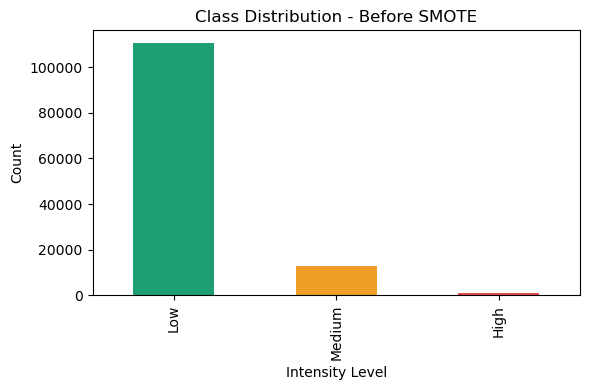

In [47]:
# عرض توزيع الكلاسات قبل SMOTE
print("\nClass distribution (before SMOTE):")
print(df_cleaned['intensity_level'].value_counts())
plt.figure(figsize=(6, 4))
df_cleaned['intensity_level'].value_counts().plot(kind='bar', color=['#1D9E75','#EF9F27','#E24B4A'])
plt.title('Class Distribution - Before SMOTE')
plt.xlabel('Intensity Level')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [48]:
print("\nExtracted Features:")
new_features = ['total_deaths','civilian_ratio','combatant_ratio',
                'deaths_per_source','trade_conflict_ratio','geo_magnitude',
                'decade','years_since_2000']
print(df_cleaned[new_features].describe())
new_features = ['total_deaths','civilian_ratio','combatant_ratio',
                'deaths_per_source','trade_conflict_ratio','geo_magnitude',
                'decade','years_since_2000']
print(df_cleaned[new_features].describe())


Extracted Features:
        total_deaths  civilian_ratio  combatant_ratio  deaths_per_source  \
count  124652.000000   124652.000000    124652.000000           116776.0   
mean       15.714758        0.196904         0.363061                inf   
std       576.454704        0.316160         0.370212                NaN   
min         0.000000        0.000000         0.000000                0.0   
25%         1.000000        0.000000         0.000000                0.5   
50%         2.000000        0.000000         0.500000                1.5   
75%         4.000000        0.500000         0.666667                NaN   
max    121848.000000        0.999975         0.999992                inf   

       trade_conflict_ratio  geo_magnitude         decade  years_since_2000  
count         124652.000000  124652.000000  124652.000000     124652.000000  
mean              23.309739      64.936612    2007.394907         11.148774  
std               21.117305      27.775489      11.126528   

## Feature Selection

In [49]:
feature_cols = [
    'year',
    'type_of_violence',
    'latitude',
    'longitude',
    'number_of_sources',
    'trade_value',
    'geo_magnitude',
    'decade',
    'years_since_2000',
    'region_enc'
    
]

In [50]:
df_model = df_cleaned.copy()

X = df_model[feature_cols].copy()
y = df_model['intensity_numeric'].copy()

In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [52]:
import numpy as np


X.replace([np.inf, -np.inf], np.nan, inplace=True)

indices_to_keep = X.dropna().index
X = X.loc[indices_to_keep]
y = y.loc[indices_to_keep]

print(f"Rows in X: {len(X)}, Rows in y: {len(y)}")

Rows in X: 124652, Rows in y: 124652


In [53]:
X.isna().sum()

year                 0
type_of_violence     0
latitude             0
longitude            0
number_of_sources    0
trade_value          0
geo_magnitude        0
decade               0
years_since_2000     0
region_enc           0
dtype: int64

In [54]:
# --- Method 1: SelectKBest (ANOVA F-test) ---
selector_anova = SelectKBest(score_func=f_classif, k='all')
selector_anova.fit(X, y)
anova_scores = pd.DataFrame({
    'Feature': feature_cols,
    'ANOVA_Score': selector_anova.scores_
}).sort_values('ANOVA_Score', ascending=False)

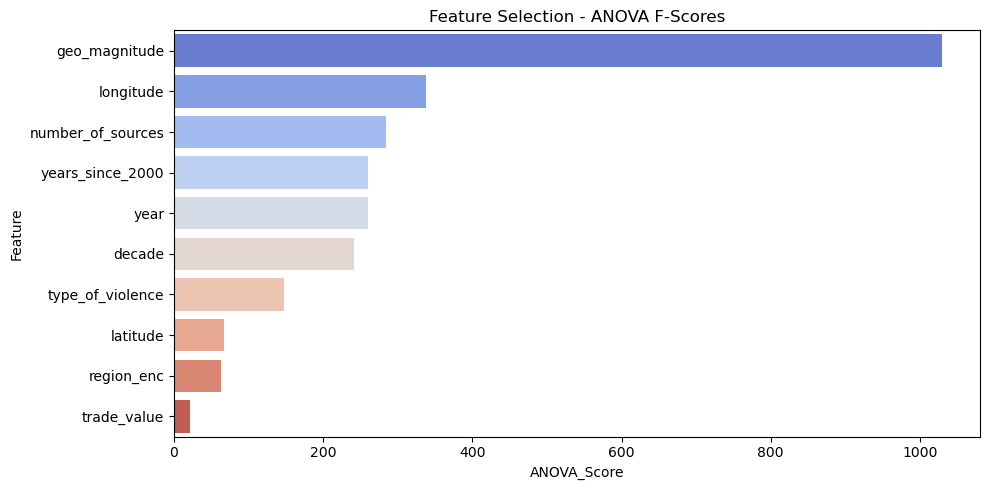

In [55]:
plt.figure(figsize=(10, 5))
sns.barplot(x='ANOVA_Score', y='Feature', data=anova_scores, palette='coolwarm')
plt.title('Feature Selection - ANOVA F-Scores')
plt.tight_layout()
plt.show()

In [56]:
# --- Method 2: Mutual Information ---
mi_scores = mutual_info_classif(X, y, random_state=42)
mi_df = pd.DataFrame({
    'Feature': feature_cols,
    'MI_Score': mi_scores
}).sort_values('MI_Score', ascending=False)


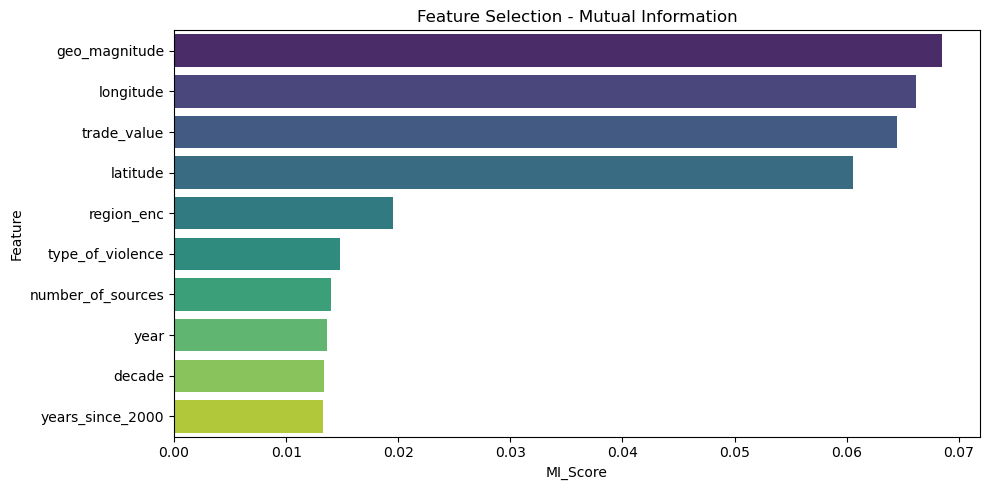

In [57]:
plt.figure(figsize=(10, 5))
sns.barplot(x='MI_Score', y='Feature', data=mi_df, palette='viridis')
plt.title('Feature Selection - Mutual Information')
plt.tight_layout()
plt.show()

In [58]:

rf_rfe = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_split=30,
    min_samples_leaf=15,
    max_features='sqrt',
    random_state=42,
    class_weight='balanced_subsample',
    n_jobs=-1
)

rfe = RFE(estimator=rf_rfe, n_features_to_select=6)
rfe.fit(X_train, y_train)

rfe_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Selected': rfe.support_,
    'Ranking': rfe.ranking_
}).sort_values('Ranking')

print("\nRFE Selected Features:")
selected_features = rfe_df[rfe_df['Selected'] == True]['Feature'].tolist()
print(selected_features)

X_train_selected = X_train[selected_features].copy()
X_test_selected  = X_test[selected_features].copy()




RFE Selected Features:
['year', 'latitude', 'longitude', 'trade_value', 'geo_magnitude', 'years_since_2000']


In [59]:
# اختيار الـ features النهائية
best_features = rfe_df[rfe_df['Selected'] == True]['Feature'].tolist()
X_selected = X[best_features]

#### Split

In [60]:
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

In [61]:
print(f"Train: {X_train.shape}  Test: {X_test.shape}")

Train: (99721, 6)  Test: (24931, 6)


#### Handle Class Imbalance (SMOTE)

In [62]:
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)
unique, counts = np.unique(y_resampled, return_counts=True)
print("Class distribution after SMOTE:")
for u, c in zip(unique, counts):
    label = [k for k,v in intensity_map.items() if v==u][0]
    print(f"  {label}: {c}")

Class distribution after SMOTE:
  Low: 88529
  Medium: 88529
  High: 88529


### Scaler

In [63]:
scaler_viz = StandardScaler()
X_viz = scaler_viz.fit_transform(X_resampled)

In [64]:
scaler = StandardScaler()
X_train_final = scaler.fit_transform(X_resampled)
X_test_final = scaler.transform(X_test)

## Dimension Reduction

### PCA Diagram

In [65]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_final)

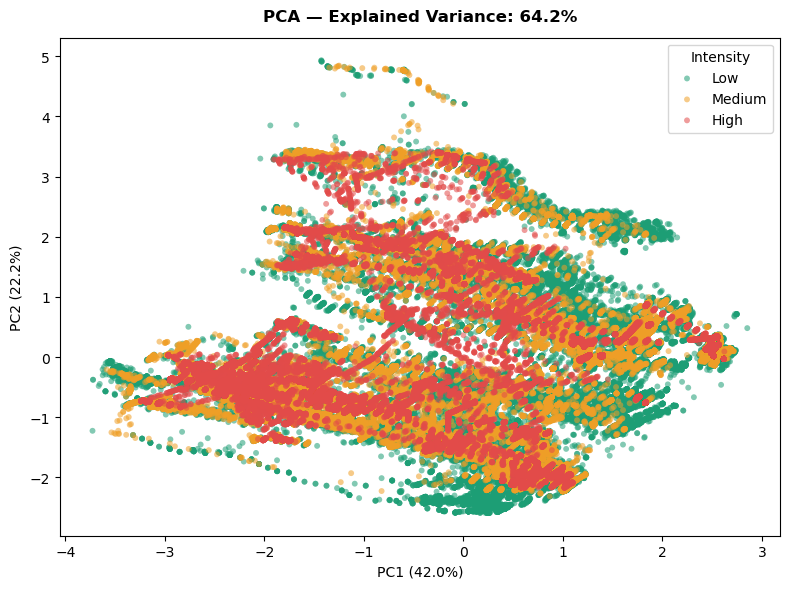

In [66]:
fig, ax = plt.subplots(figsize=(8, 6))
colors_list = ['#1D9E75','#EF9F27','#E24B4A']
for i, (color, label) in enumerate(zip(colors_list, ['Low','Medium','High'])):
    mask = y_resampled == i
    ax.scatter(X_pca[mask,0],
                X_pca[mask,1],c=color, label=label,
                  alpha=0.55, s=18, edgecolors='none')
ax.legend(title='Intensity')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title(f'PCA — Explained Variance: {pca.explained_variance_ratio_.sum():.1%}', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### t-SNE Diagram

In [67]:
sample_idx = np.random.choice(len(X_viz), min(3000, len(X_viz)), replace=False)
tsne   = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_viz[sample_idx])
y_tsne = y_resampled[sample_idx]

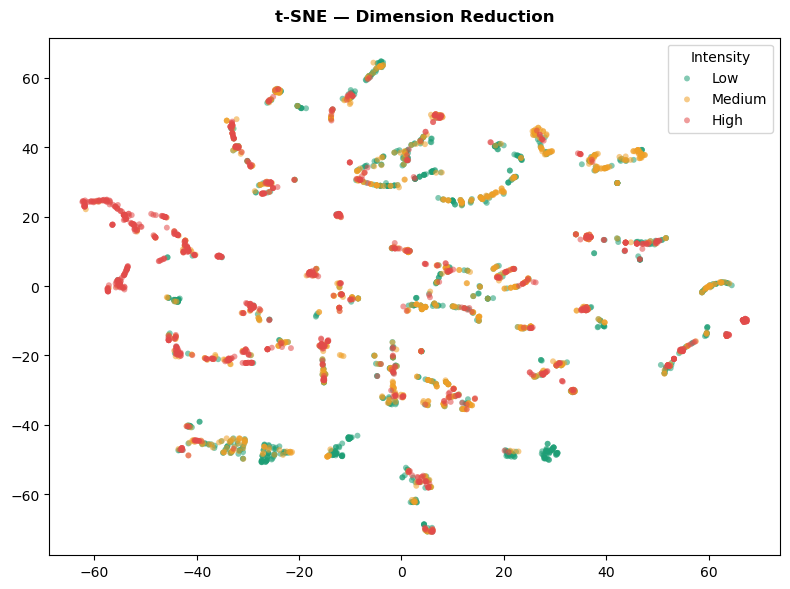

In [68]:
fig, ax = plt.subplots(figsize=(8, 6))
for i, (color, label) in enumerate(zip(colors_list, ['Low','Medium','High'])):
    mask = y_tsne == i
    ax.scatter(X_tsne[mask,0], X_tsne[mask,1], c=color,
                label=label, alpha=0.55, s=18, edgecolors='none')
ax.legend(title='Intensity')
ax.set_title('t-SNE — Dimension Reduction', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

 Models


In [69]:
models = {
    'CatBoost': CatBoostClassifier(
        iterations=200,
        learning_rate=0.05,
        depth=4,
        l2_leaf_reg=5,
        random_state=42,
        verbose=0,
        auto_class_weights='Balanced'
    ),

    'Logistic Regression': LogisticRegression(
        C=0.1,
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    ),
}


Model        : Random Forest (No SMOTE)
CV Accuracy  : 0.4934 ± 0.0048
Test Accuracy: 0.4860
Overfit Gap  : 0.0074  ✓ OK
Balanced Accuracy: 0.5967
Macro F1         : 0.323

Classification Report:
              precision    recall  f1-score   support

         Low       0.96      0.46      0.63     22133
      Medium       0.15      0.67      0.24      2587
        High       0.06      0.66      0.10       211

    accuracy                           0.49     24931
   macro avg       0.39      0.60      0.32     24931
weighted avg       0.87      0.49      0.58     24931



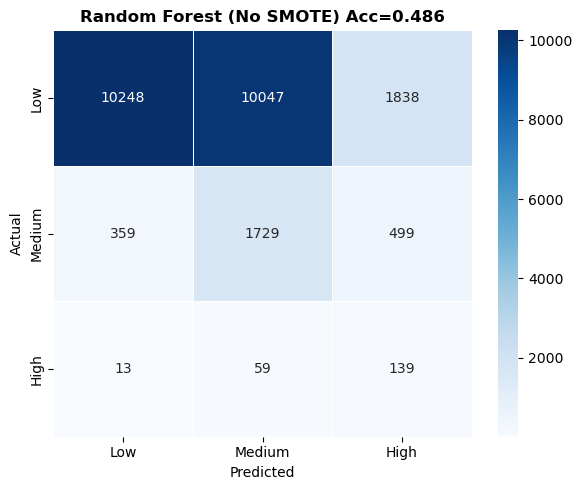

In [70]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_split=30,
    min_samples_leaf=15,
    max_features='sqrt',
    random_state=42,
    class_weight='balanced_subsample',
    n_jobs=-1
)

# Cross-validation on original train only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = cross_val_score(
    rf_model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Train and test
rf_model.fit(X_train_selected, y_train)
y_pred = rf_model.predict(X_test_selected)

test_acc = accuracy_score(y_test, y_pred)
gap = abs(cv_acc.mean() - test_acc)

print(f"\n{'='*50}")
print("Model        : Random Forest (No SMOTE)")
print(f"CV Accuracy  : {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Overfit Gap  : {gap:.4f}  {'⚠ check' if gap > 0.05 else '✓ OK'}")
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("Macro F1         :", round(f1_score(y_test, y_pred, average='macro'), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Low', 'Medium', 'High']))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High'],
    linewidths=0.5,
    linecolor='white'
)
plt.title(f'Random Forest (No SMOTE) Acc={test_acc:.3f}', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


In [71]:

rf_no_smote_model = rf_model
rf_no_smote_test_acc = test_acc
rf_no_smote_cv_acc = cv_acc
rf_no_smote_pred = y_pred.copy()


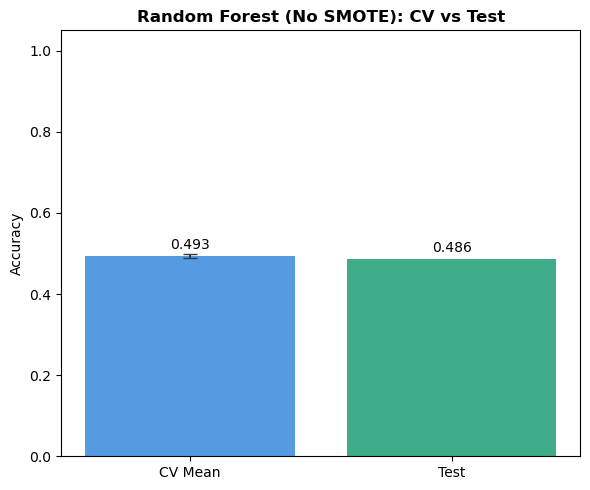

In [72]:
# =========================================
# Bar Chart for Random Forest (No SMOTE) only
# =========================================
import matplotlib.pyplot as plt
import numpy as np

rf_cv_mean = rf_no_smote_cv_acc.mean()
rf_cv_std = rf_no_smote_cv_acc.std()
rf_test = rf_no_smote_test_acc

labels = ['CV Mean', 'Test']
values = [rf_cv_mean, rf_test]
colors = ['#378ADD', '#1D9E75']

plt.figure(figsize=(6, 5))
bars = plt.bar(labels, values, color=colors, alpha=0.85)

# error bar 
plt.errorbar(
    0, rf_cv_mean,
    yerr=rf_cv_std,
    fmt='none',
    color='#2C3E50',
    capsize=5,
    linewidth=1.5
)

plt.ylim(0, 1.05)
plt.ylabel('Accuracy')
plt.title('Random Forest (No SMOTE): CV vs Test', fontweight='bold')

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 0.01, f'{h:.3f}',
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


In [73]:
# =========================================
# Compare Models (CatBoost + Logistic only)
# =========================================
results = {}
cv_results = {}
trained_models = {}
test_predictions = {}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    cv_acc = cross_val_score(
        model,
        X_train_final,
        y_resampled,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )
    cv_results[name] = cv_acc

    model.fit(X_train_final, y_resampled)
    y_pred = model.predict(X_test_final)

    test_acc = accuracy_score(y_test, y_pred)
    results[name] = test_acc
    trained_models[name] = model
    test_predictions[name] = y_pred.copy()

    gap = abs(cv_acc.mean() - test_acc)

    print(f"\n{'='*50}")
    print(f"Model        : {name}")
    print(f"CV Accuracy  : {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")
    print(f"Overfit Gap  : {gap:.4f}  {'⚠ check' if gap > 0.05 else '✓ OK'}")
    print(classification_report(y_test, y_pred, target_names=['Low', 'Medium', 'High']))


Model        : CatBoost
CV Accuracy  : 0.6455 ± 0.0017
Test Accuracy: 0.6075
Overfit Gap  : 0.0380  ✓ OK
              precision    recall  f1-score   support

         Low       0.96      0.61      0.75     22133
      Medium       0.18      0.57      0.28      2587
        High       0.05      0.71      0.10       211

    accuracy                           0.61     24931
   macro avg       0.40      0.63      0.37     24931
weighted avg       0.87      0.61      0.69     24931


Model        : Logistic Regression
CV Accuracy  : 0.4873 ± 0.0008
Test Accuracy: 0.4726
Overfit Gap  : 0.0147  ✓ OK
              precision    recall  f1-score   support

         Low       0.92      0.49      0.64     22133
      Medium       0.11      0.36      0.17      2587
        High       0.02      0.54      0.04       211

    accuracy                           0.47     24931
   macro avg       0.35      0.46      0.28     24931
weighted avg       0.83      0.47      0.58     24931



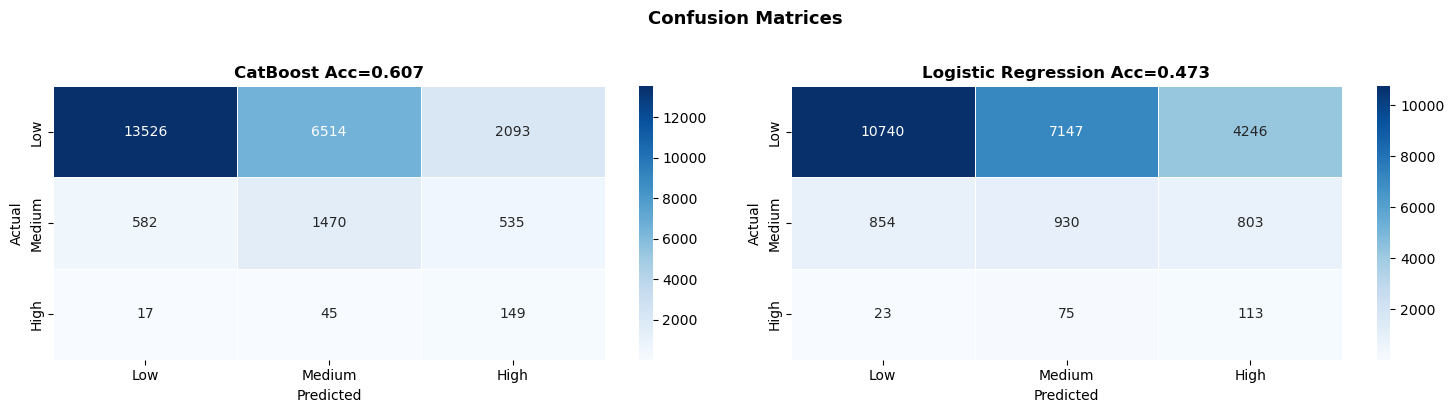

In [75]:
# =========================================
# Confusion Matrices
# =========================================
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

for ax, name in zip(axes, models.keys()):
    y_pred_plot = trained_models[name].predict(X_test_final)

    cm = confusion_matrix(y_test, y_pred_plot, labels=[0, 1, 2])

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Low', 'Medium', 'High'],
        yticklabels=['Low', 'Medium', 'High'],
        linewidths=0.5,
        linecolor='white',
        ax=ax
    )

    ax.set_title(f'{name} Acc={results[name]:.3f}', fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

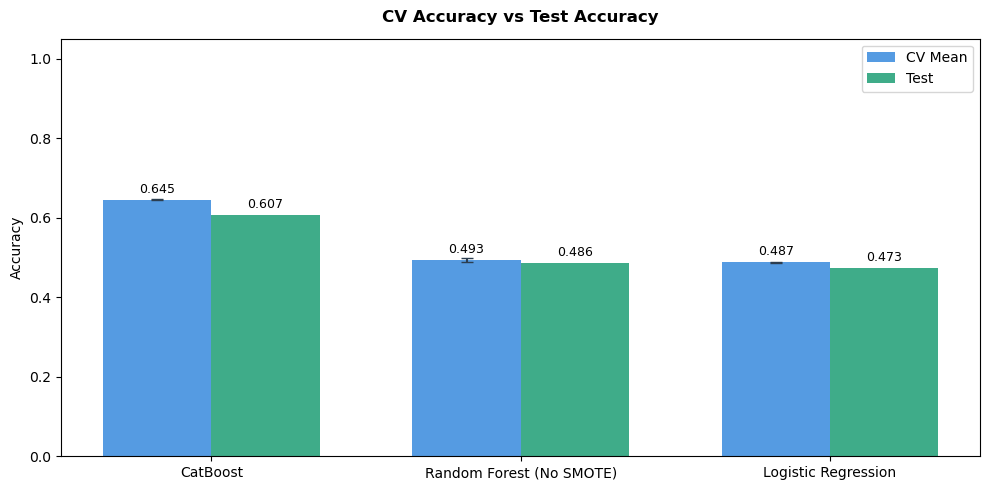

In [79]:
# =========================================
# CV vs Test Accuracy
# CatBoost + RF (No SMOTE) + Logistic
# =========================================
import numpy as np
import matplotlib.pyplot as plt

labels = ['CatBoost', 'Random Forest (No SMOTE)', 'Logistic Regression']

cv_means = [
    cv_results['CatBoost'].mean(),
    rf_no_smote_cv_acc.mean(),
    cv_results['Logistic Regression'].mean()
]

cv_stds = [
    cv_results['CatBoost'].std(),
    rf_no_smote_cv_acc.std(),
    cv_results['Logistic Regression'].std()
]

test_vals = [
    results['CatBoost'],
    rf_no_smote_test_acc,
    results['Logistic Regression']
]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

bars1 = ax.bar(
    x - width/2,
    cv_means,
    width,
    label='CV Mean',
    color='#378ADD',
    alpha=0.85
)

bars2 = ax.bar(
    x + width/2,
    test_vals,
    width,
    label='Test',
    color='#1D9E75',
    alpha=0.85
)

ax.errorbar(
    x - width/2,
    cv_means,
    yerr=cv_stds,
    fmt='none',
    color='#2C3E50',
    capsize=4,
    linewidth=1.5
)

# مهم جدًا: دول اللي بيظهروا الأسماء
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=0, fontsize=10)

ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1.05)
ax.set_title('CV Accuracy vs Test Accuracy', fontweight='bold', pad=12)
ax.legend()

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        h + 0.01,
        f'{h:.3f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()


## Save Model

In [ ]:
# jo.dump(best_model, "best_conflict_intensity_model.pkl")

In [ ]:
# jo.dump(scaler, 'final_scaler.pkl')

## Deployment